<a href="https://colab.research.google.com/github/Amulya-Rao-mj/ML2_lab--Amulya-Rao-M-J--4NI23CI013/blob/main/LAB8_SOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA


In [3]:

from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

# Display dataset
print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nDataset information:")
df.info()


Saving breast_cancer.csv to breast_cancer.csv
First five rows:


,,,,,,,,,,,,,,,,,,,,,,,,,,,569,30,malignant,benign
17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset shape: (569, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
MultiIndex: 569 entries, (np.float64(17.99), np.float64(10.38), np.float64(122.8), np.float64(1001.0), np.float64(0.1184), np.float64(0.2776), np.float64(0.3001), np.float64(0.1471), np.float64(0.2419), np.float64(0.07871), np.float64(1.095), np.float64(0.9053), np.float64(8.589), np.float64(153.4), np.float64(0.006399), np.float64(0.04904), np.float64(0.05373), np.float64(0.01587), np.float64(0.03003), np.float64(0.006193), np.float64(25.38), np.float64(17.33), np.float64(184.6), np.float64(2019.0), np.float64(0.1622), np.float64(0.6656), np.float64(0.7119)) to (np.float64(7.76), np.float64(24.54), np.float64(47.92), np.float64(181.0), np.float64(0.05263), np.float64(0.04362), np.float64(0.0), np.float64(0.0), np.float64(0.1587), np.float64(0.05884), np.float64(0.3857), np.float64(1.428), np.float64(2.548), np.float64(19.15), np.float64(0.007189), np.float64(0.00466), np.float64(0.0), np.float64(0.0),

In [4]:

# Remove duplicate rows
df = df.drop_duplicates()

# Select numerical columns
data = df.select_dtypes(include=np.number)

# Handle missing values
data = data.fillna(data.median())

# Normalize the data
scaler = MinMaxScaler()
X = scaler.fit_transform(data)

print("Preprocessed data shape:", X.shape)
print(X[:5])


Preprocessed data shape: (569, 4)
[[0.91202749 0.59846245 0.41886396 0.        ]
 [0.63917526 0.23358959 0.22287813 0.        ]
 [0.83505155 0.40370589 0.21343303 0.        ]
 [0.88487973 1.         0.77371114 0.        ]
 [0.55841924 0.15750049 0.14259478 0.        ]]


In [5]:

!pip install MiniSom

from minisom import MiniSom


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for MiniSom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=f3fad0aa2141ea507f089234114b506f54ce502db9db969391514f2cdb60079b
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built MiniSom


In [6]:

# Define SOM dimensions
som_rows = 10
som_cols = 10

# Initialize SOM
som = MiniSom(
    x=som_rows,
    y=som_cols,
    input_len=X.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights
som.random_weights_init(X)

# Train SOM
som.train_random(X, num_iteration=1000)

print("SOM training completed!")


SOM training completed!


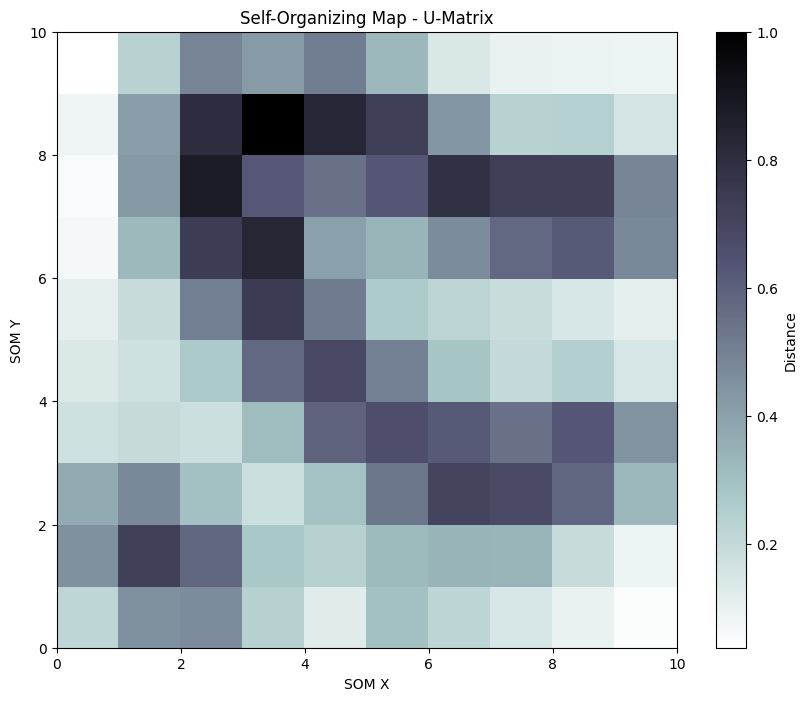

In [7]:

plt.figure(figsize=(10, 8))

plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Distance')

plt.title("Self-Organizing Map - U-Matrix")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()


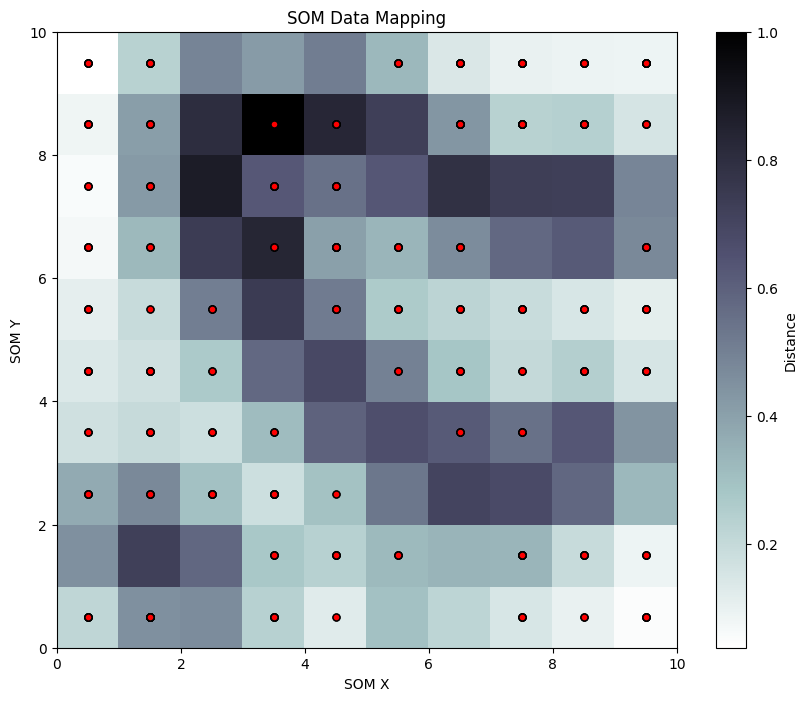

In [8]:

plt.figure(figsize=(10, 8))

plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Distance')

for i, x in enumerate(X):
    w = som.winner(x)

    plt.plot(
        w[0] + 0.5,
        w[1] + 0.5,
        'o',
        markerfacecolor='red',
        markeredgecolor='black',
        markersize=5
    )

plt.title("SOM Data Mapping")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()


In [9]:

from sklearn.cluster import KMeans

# Get trained SOM weights
weights = som.get_weights()

# Reshape weights into a 2D array
weights_reshaped = weights.reshape(-1, X.shape[1])

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(weights_reshaped)

# Assign each data point to its BMU's cluster
cluster_labels = []

for x in X:
    winner = som.winner(x)
    neuron_index = winner[0] * som_cols + winner[1]

    cluster_labels.append(kmeans.labels_[neuron_index])

# Add cluster labels to original dataframe
df = df.loc[data.index].copy()
df['Cluster'] = cluster_labels

print(df[['Cluster']].value_counts().sort_index())
display(df.head())


Cluster
0          212
1          357
Name: count, dtype: int64


,,,,,,,,,,,,,,,,,,,,,,,,,,,569,30,malignant,benign,Cluster
17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,0
20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,0
19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,0
11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,0
20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,0


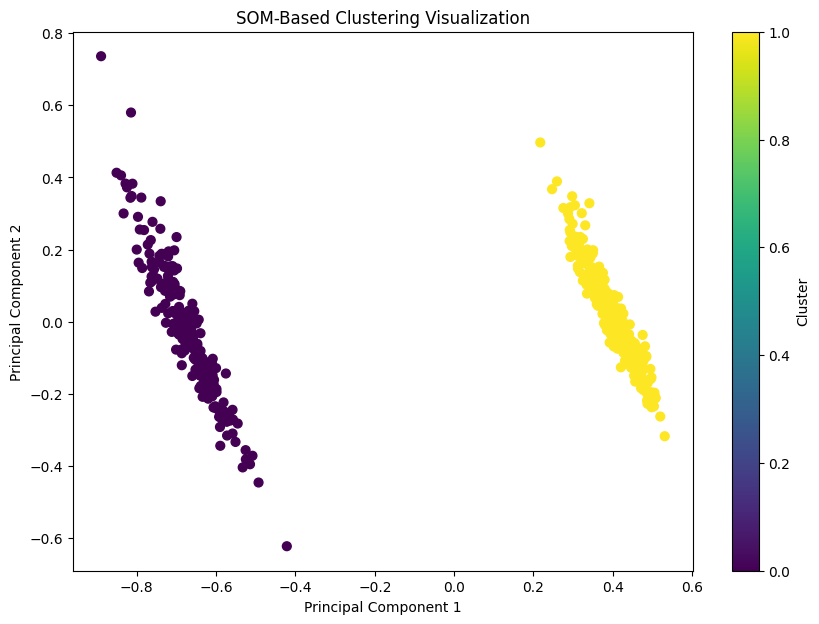

In [10]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=40
)

plt.title("SOM-Based Clustering Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()


In [11]:

from sklearn.metrics import silhouette_score

score = silhouette_score(X, cluster_labels)

print("Silhouette Score:", score)


Silhouette Score: 0.7697273753369656
